# Doanh thu tập trung ở đâu?
## Visual Analytics với UCI Online Retail
**Sinh viên/Nhóm:** … · **Lớp:** …

Mục tiêu: xác định mức tập trung doanh số theo thời gian, sản phẩm, thị trường và khách hàng; kiểm tra giá trị hủy. Chạy các ô từ trên xuống bằng **Run All**. Notebook dùng các hàm trong `src/`; mỗi bước bên dưới cho biết đầu vào, kết quả và cách đọc. Số liệu tiền dùng GBP; dấu phẩy phân tách hàng nghìn, dấu chấm phân tách thập phân.

## 1. Chuẩn bị môi trường
Pandas làm việc với bảng; Matplotlib vẽ biểu đồ. Ô này tìm thư mục dự án và nạp các hàm xử lý. Cài thư viện theo README trước khi chạy.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src').exists(), 'Hãy mở notebook trong thư mục dự án.'
sys.path.insert(0, str(ROOT))
if (ROOT / '.packages').exists():
    sys.path.insert(0, str(ROOT / '.packages'))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.analysis import load_data, clean_data, summarize, save_tables, make_charts, validate
from src.deliverables import build_report, build_presentation, chart_stories
print('Thư mục dự án:', ROOT)

Thư mục dự án: D:\bi_bt7


## 2. Đọc và hiểu dữ liệu
Nguồn: [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online-retail), Chen (2015), DOI: 10.24432/C5BW33, CC BY 4.0. Có 541.909 dòng hàng và 8 cột; **một dòng không phải một đơn hàng**. `InvoiceNo` và `StockCode` là ID; `Quantity`, `UnitPrice` là số; `InvoiceDate` là thời gian; các cột còn lại mô tả sản phẩm, khách và thị trường.

In [2]:
raw = load_data(ROOT)
print('Kích thước:', raw.shape)
display(raw.head())
display(raw.dtypes.to_frame('Kiểu dữ liệu'))

Kích thước: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,Kiểu dữ liệu
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[us]
UnitPrice,float64
CustomerID,float64
Country,str


## 3. Kiểm tra chất lượng và phân nhóm
- Bán: không mã C, số lượng dương, đơn giá dương và đủ mã/ngày/quốc gia.
- Hủy: mã C, số lượng âm, đơn giá dương và đủ mã/ngày/quốc gia.
- Còn lại: lưu riêng, không cộng vào hai nhóm trên.

Giữ dòng thiếu CustomerID trong doanh số, chỉ loại khỏi phân tích khách hàng. Giữ dòng trùng vì không có mã dòng hàng xác nhận lỗi. Các cờ kiểm tra có thể chồng lấn; chỉ ba nhóm bán/hủy/khác mới tạo thành phép phân hoạch dữ liệu.

In [3]:
data = clean_data(raw)
display(data['quality'])
display(data['audit'])
display(pd.Series(data['issues'], name='Kết quả kiểm tra'))

,Cot,Kieu_du_lieu,So_thieu,Ty_le_thieu_pct,So_gia_tri_khac_nhau
0,InvoiceNo,object,0,0.000000,25900
1,StockCode,object,0,0.000000,4070
2,Description,object,1454,0.268311,4223
3,Quantity,int64,0,0.000000,722
4,InvoiceDate,datetime64[us],0,0.000000,23260
5,UnitPrice,float64,0,0.000000,1630
6,CustomerID,float64,135080,24.926694,4372
7,Country,str,0,0.000000,38


,Buoc,So_dong,Quy_tac
0,Dữ liệu thô,541909,Giữ nguyên 8 cột nguồn; 1 dòng là 1 dòng hàng
1,Giao dịch bán hợp lệ,530104,"Không mã C, Quantity > 0, UnitPrice > 0; đủ kh..."
2,Giao dịch hủy hợp lệ,9288,"Mã C, Quantity < 0, UnitPrice > 0; đủ khóa và ..."
3,Dòng bất thường / không hợp lệ,2517,Phần còn lại; lưu riêng để kiểm tra
4,Bán có mã khách hàng,397884,Chỉ tập này được dùng phân tích khách hàng
5,Bán thiếu mã khách hàng,132220,Vẫn giữ trong doanh số
6,Dòng trùng hoàn toàn (sau dòng đầu),5268,Giữ lại: chưa có bằng chứng là lỗi nhập lặp


quantity_negative              10624.00
price_zero                      2515.00
price_negative                     2.00
negative_quantity_without_C     1336.00
C_without_negative_quantity        0.00
duplicate_sale_value           24573.74
duplicate_cancel_value          2832.76
Name: Kết quả kiểm tra, dtype: float64

## 4. Tính chỉ số ở đúng cấp độ
`LineValue = Quantity × UnitPrice`. Dùng `groupby(InvoiceNo)` để cộng giá trị đơn, `nunique(InvoiceNo)` để đếm số đơn. Khách hàng chỉ lấy CustomerID đã biết. Doanh số bán và giá trị hủy được báo cáo riêng; chưa ghép chứng từ nên không gọi chênh lệch là lợi nhuận. Tháng cuối chưa đủ được đánh dấu, không so như một tháng hoàn chỉnh.

In [4]:
tables = summarize(data)
save_tables(ROOT, data, tables)
display(pd.Series(tables['stats'], name='Giá trị'))
display(tables['monthly'])
display(tables['markets'].head(6))

raw_rows                                          541909
sale_rows                                         530104
cancel_rows                                         9288
other_rows                                          2517
orders                                             19960
customers                                           4338
sales                                       10666684.544
cancellation                                   896812.49
period_balance                               9769872.054
cancel_to_sales_pct                             8.407603
uk_share_pct                                   84.611315
identified_sales                             8911407.904
identified_share_pct                           83.544309
top10_customer_n                                     434
top10_customer_share_pct                       61.375066
mean_order                                    534.403033
median_order                                     303.835
p99_order                      

,Sales,Cancellation,Partial
InvoiceDate,,,
2010-12,823746.140,74789.12,False
2011-01,691364.560,131364.30,False
2011-02,523631.890,25569.24,False
2011-03,717639.360,34372.28,False
2011-04,537808.621,44601.50,False
2011-05,770536.020,47202.51,False
2011-06,761739.900,70616.78,False
2011-07,719221.191,37921.08,False
2011-08,759138.380,54333.75,False


,Sales,Cancellation,CancellationToSalesPct
Country,,,
United Kingdom,9025222.084,815291.60,9.033480
Netherlands,285446.340,784.80,0.274938
EIRE,283453.960,20177.14,7.118313
Germany,228867.140,7168.93,3.132354
France,209715.110,12311.21,5.870445
Australia,138521.310,1444.04,1.042468


## 5. Phân tích bằng sáu loại biểu đồ
Các hình dùng chung màu và đơn vị; ghi rõ phạm vi hiển thị. Histogram chỉ hiện đến P99, boxplot ẩn điểm ngoài râu, scatter dùng log; **không xóa ngoại lệ khỏi KPI**.

In [5]:
figures = make_charts(ROOT, data, tables)
stories = chart_stories(tables)

### Góc nhìn 1
Đọc theo thứ tự: mục đích biểu đồ → bằng chứng → ý nghĩa → hành động.

**01 · Xu hướng: xác định giai đoạn cần ưu tiên**

Line chart nối các tháng đầy đủ để thể hiện biến động theo thời gian. Kỳ chưa đủ được đánh dấu riêng.

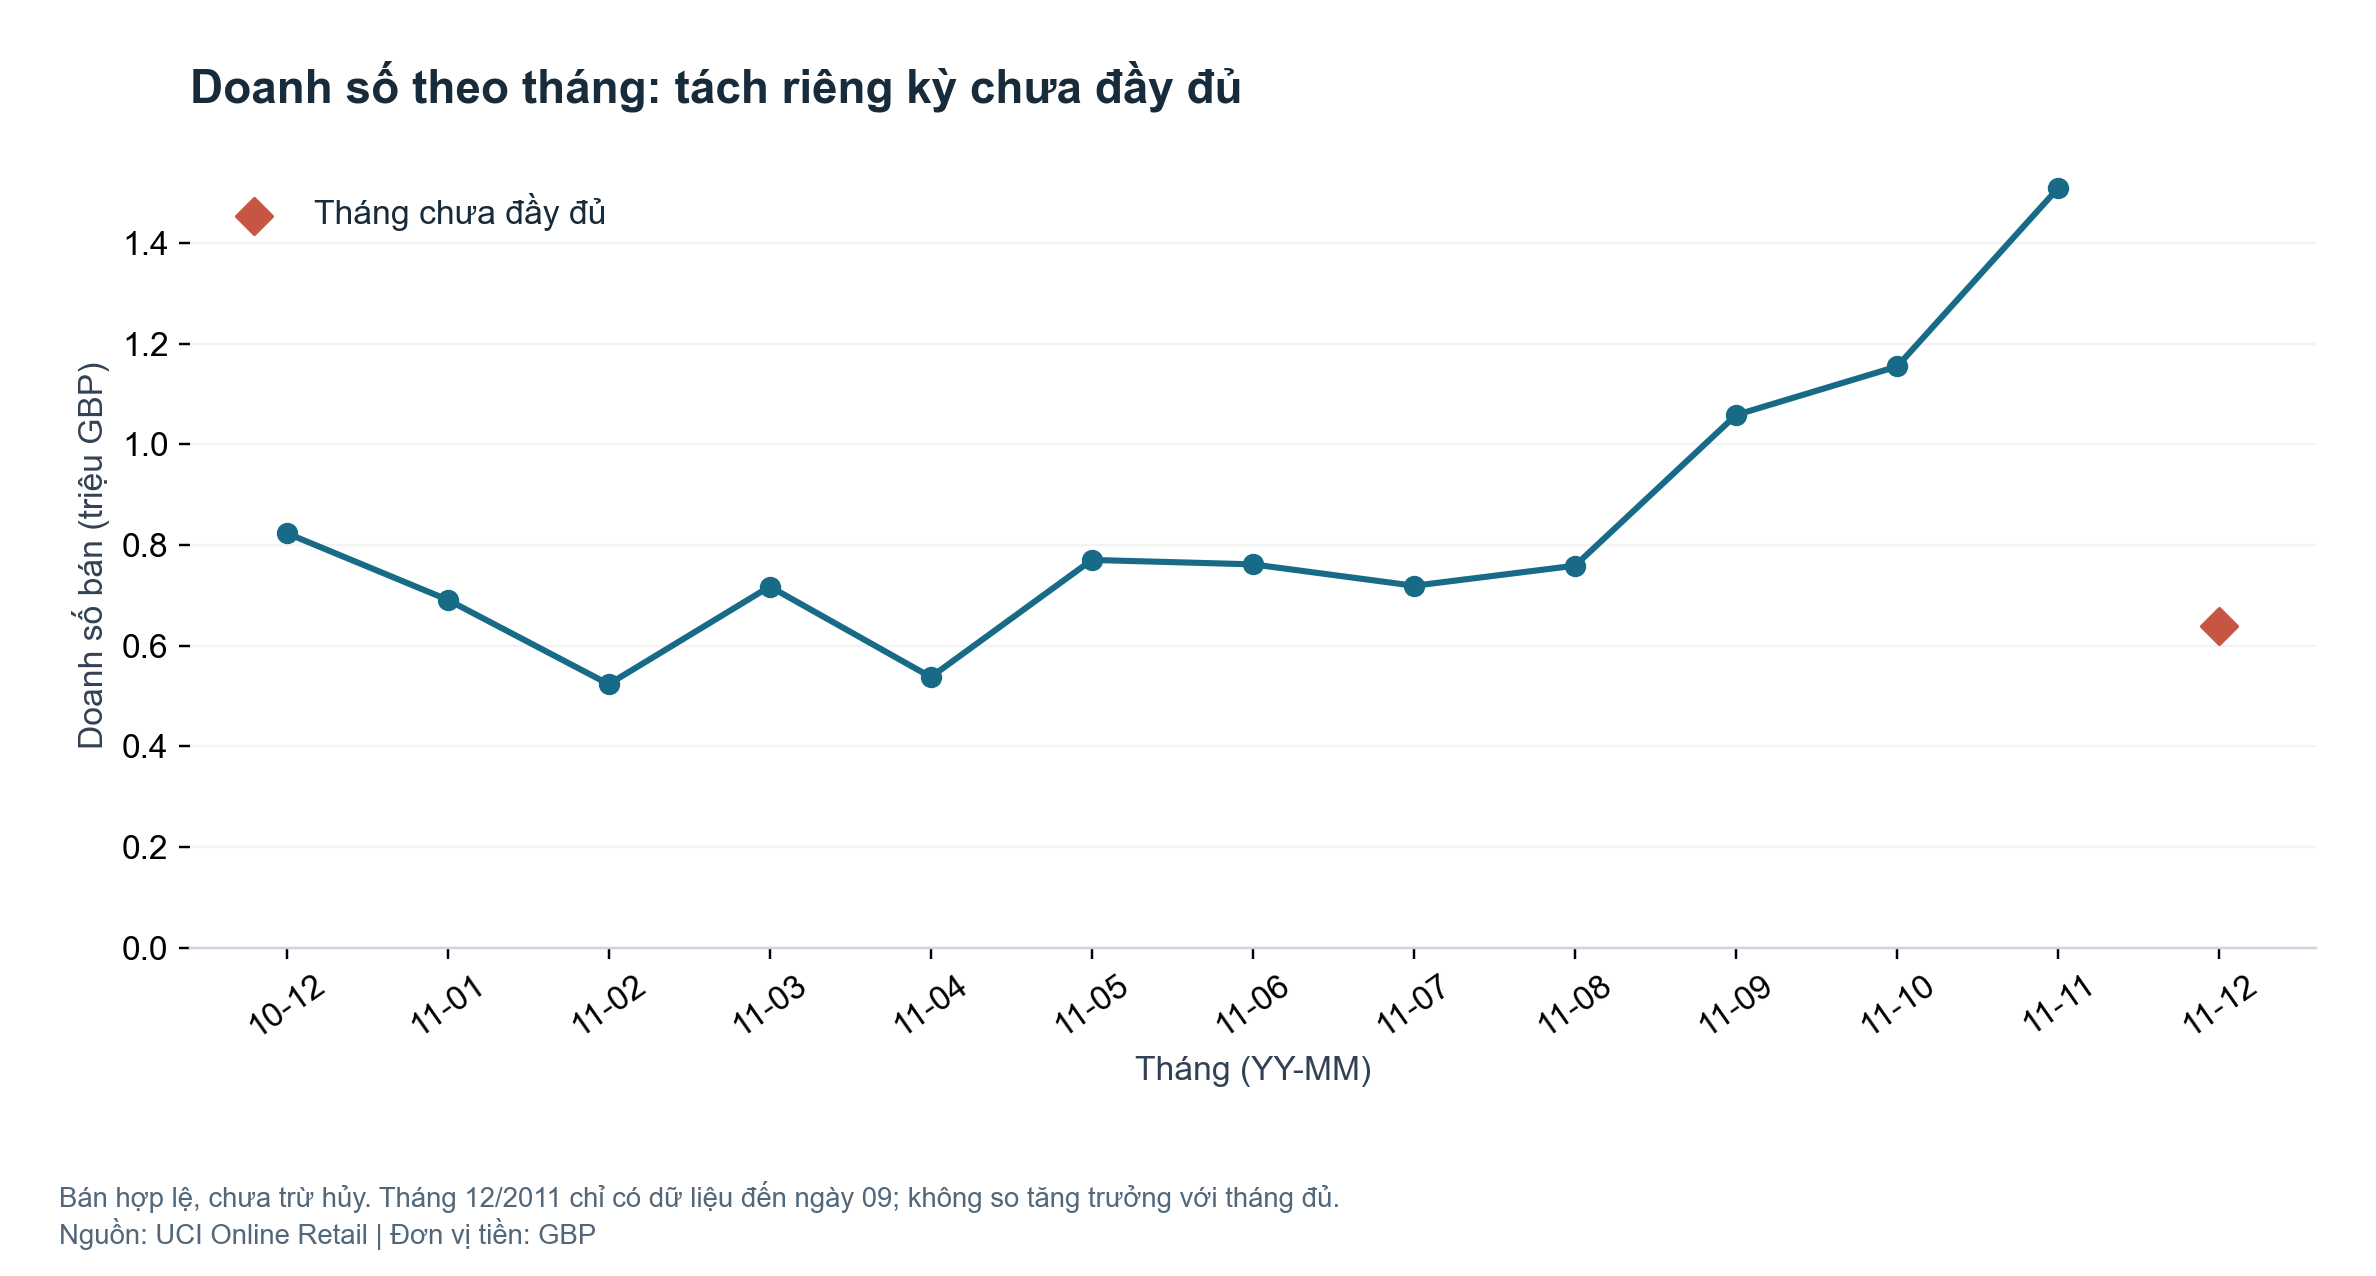

**Phát hiện:** Trong các tháng đầy đủ quan sát được, 2011-11 có doanh số cao nhất: 1,509,496.33 GBP. Tháng đầy đủ cuối cùng có doanh số 1,509,496.33 GBP, thay đổi +30.69% so với tháng đầy đủ trước đó.

**Diễn giải:** Mức tăng gợi ý cần chuẩn bị năng lực phục vụ cho giai đoạn cuối năm, nhưng một năm dữ liệu chưa đủ chứng minh mùa vụ lặp lại. Chưa có dữ liệu chiến dịch hoặc tồn kho để kết luận nguyên nhân tăng.

**Hành động:** Ưu tiên kiểm tra kế hoạch hàng hóa và nhân lực trước giai đoạn cao điểm; kiểm chứng bằng dữ liệu nhiều năm. Không diễn giải tháng 12/2011 thấp là suy giảm vì chỉ quan sát đến ngày 09.

In [6]:
st = stories[0]
display(Markdown('**' + st['title'] + '**\n\n' + st['purpose']))
display(Image(filename=str(figures[0]), width=950))
for label, key in [('Phát hiện', 'finding'), ('Diễn giải', 'meaning'), ('Hành động', 'action')]:
    display(Markdown('**' + label + ':** ' + st[key]))

### Góc nhìn 2
Đọc theo thứ tự: mục đích biểu đồ → bằng chứng → ý nghĩa → hành động.

**02 · Sản phẩm: chọn nơi ưu tiên nguồn lực**

Bar chart ngang giúp so sánh và đọc tên sản phẩm dài; trục giá trị bắt đầu từ 0.

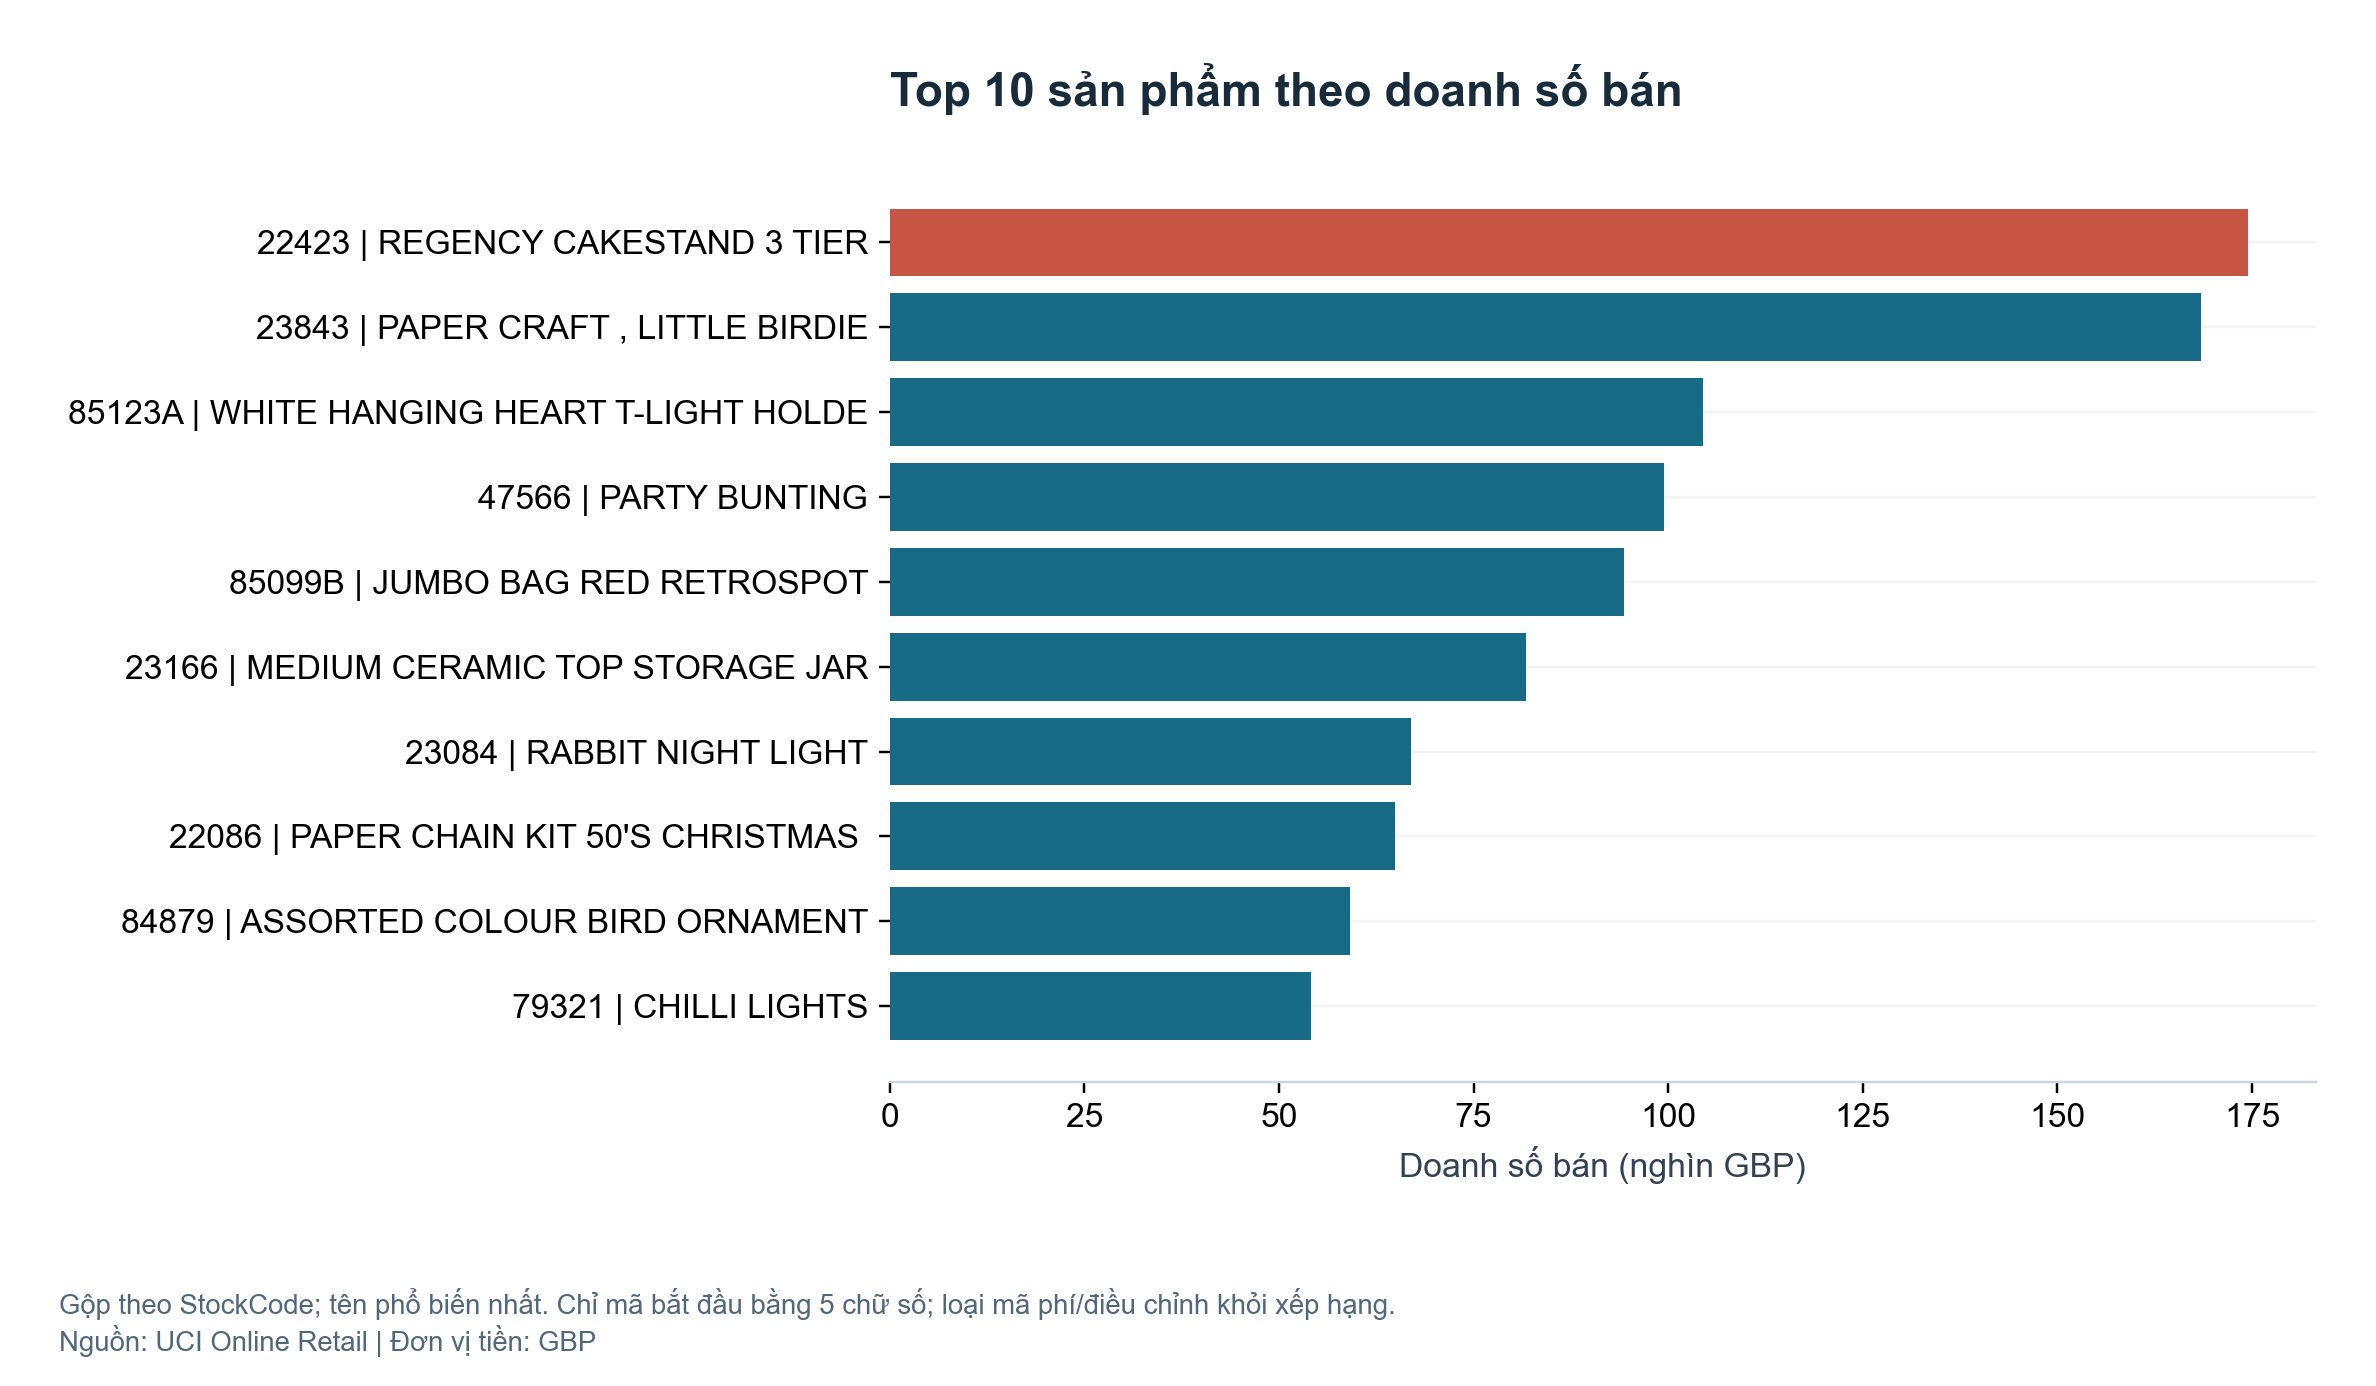

**Phát hiện:** Sản phẩm dẫn đầu là REGENCY CAKESTAND 3 TIER (mã 22423), đạt 174,484.74 GBP. Top 10 mã sản phẩm chiếm 9.08% tổng doanh số bán hợp lệ.

**Diễn giải:** Xếp hạng theo mã, chưa trừ hủy. Mã 23843 có dòng bán 168,469.60 GBP và dòng C581484 hủy cùng giá trị; chưa khẳng định ghép đơn chính xác, nhưng đây là tín hiệu cần kiểm tra trước khi xem doanh số gộp là nhu cầu bền vững. Các mã không bắt đầu bằng 5 chữ số, tổng 395,649.93 GBP, vẫn có trong KPI nhưng không vào xếp hạng. Quy tắc nhận diện sản phẩm cần đối chiếu danh mục chính thức.

**Hành động:** Rà soát khả năng đáp ứng của nhóm sản phẩm dẫn đầu. Chưa quyết định tăng nhập chỉ từ doanh số: cần bổ sung tồn kho, biên lợi nhuận và giá trị hủy theo sản phẩm.

In [7]:
st = stories[1]
display(Markdown('**' + st['title'] + '**\n\n' + st['purpose']))
display(Image(filename=str(figures[1]), width=950))
for label, key in [('Phát hiện', 'finding'), ('Diễn giải', 'meaning'), ('Hành động', 'action')]:
    display(Markdown('**' + label + ':** ' + st[key]))

### Góc nhìn 3
Đọc theo thứ tự: mục đích biểu đồ → bằng chứng → ý nghĩa → hành động.

**03 · Thị trường: nhìn đồng thời quy mô và giá trị hủy**

Stacked bar 100% so sánh cơ cấu bán và trị tuyệt đối hủy giữa sáu thị trường có doanh số bán lớn nhất.

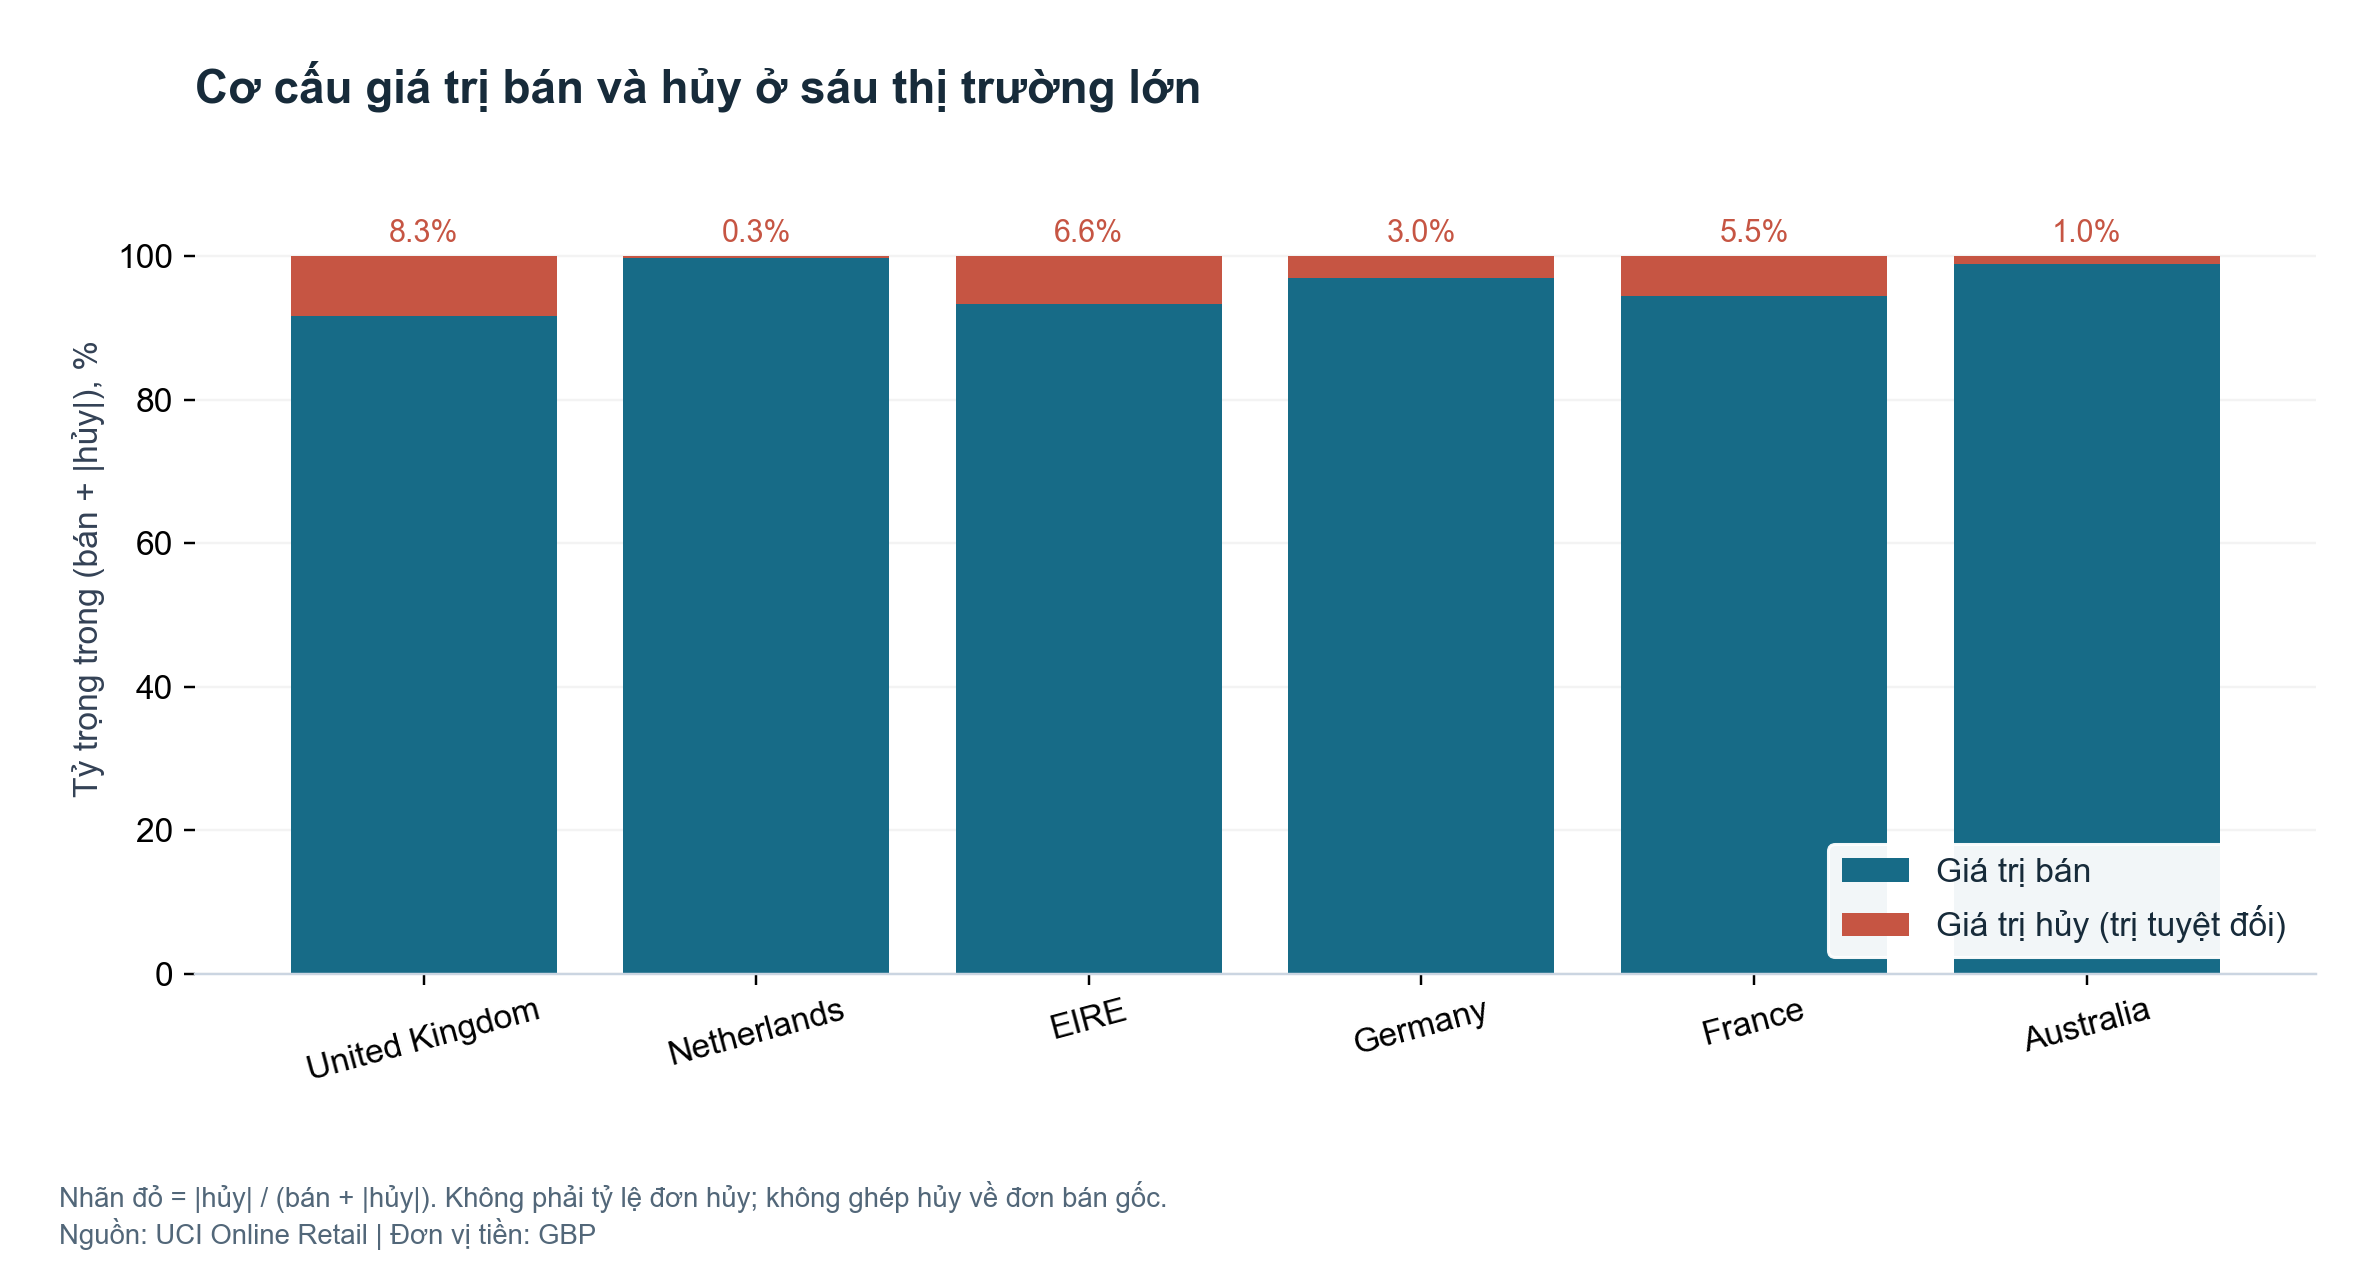

**Phát hiện:** United Kingdom đóng góp 84.61% doanh số bán. Tổng giá trị hủy là 896,812.49 GBP, bằng 8.41% doanh số bán. Trong sáu thị trường lớn, United Kingdom có |hủy|/bán cao nhất, 9.03%. Hai chứng từ hủy lớn nhất chiếm 27.39% tổng giá trị hủy (245,653.20 GBP).

**Diễn giải:** Nhãn đỏ trên hình dùng |hủy|/(bán + |hủy|), khác chỉ số |hủy|/bán trong phần diễn giải. Hai mẫu số được ghi rõ để không nhầm cơ cấu với tỷ lệ hủy trên doanh số. Giao dịch hủy có thể thuộc đơn ngoài kỳ; mã C có cả Manual/AMAZONFEE, vì vậy không coi đây là tỷ lệ khách trả hàng hoặc tỷ lệ đơn bị hủy. Bảng cancellation_invoices.csv và large_cancellation_lines.csv lưu bằng chứng để đối soát.

**Hành động:** Ưu tiên kiểm tra chứng từ hủy có giá trị lớn ở thị trường đóng góp chính. Muốn tìm nguyên nhân cần ghép chứng từ gốc, lý do hủy và thông tin vận chuyển.

In [8]:
st = stories[2]
display(Markdown('**' + st['title'] + '**\n\n' + st['purpose']))
display(Image(filename=str(figures[2]), width=950))
for label, key in [('Phát hiện', 'finding'), ('Diễn giải', 'meaning'), ('Hành động', 'action')]:
    display(Markdown('**' + label + ':** ' + st[key]))

### Góc nhìn 4
Đọc theo thứ tự: mục đích biểu đồ → bằng chứng → ý nghĩa → hành động.

**04 · Phân phối: vì sao số trung bình dễ gây hiểu lầm?**

Histogram thể hiện tần suất theo khoảng giá trị đơn. Mỗi InvoiceNo chỉ đóng góp một quan sát.

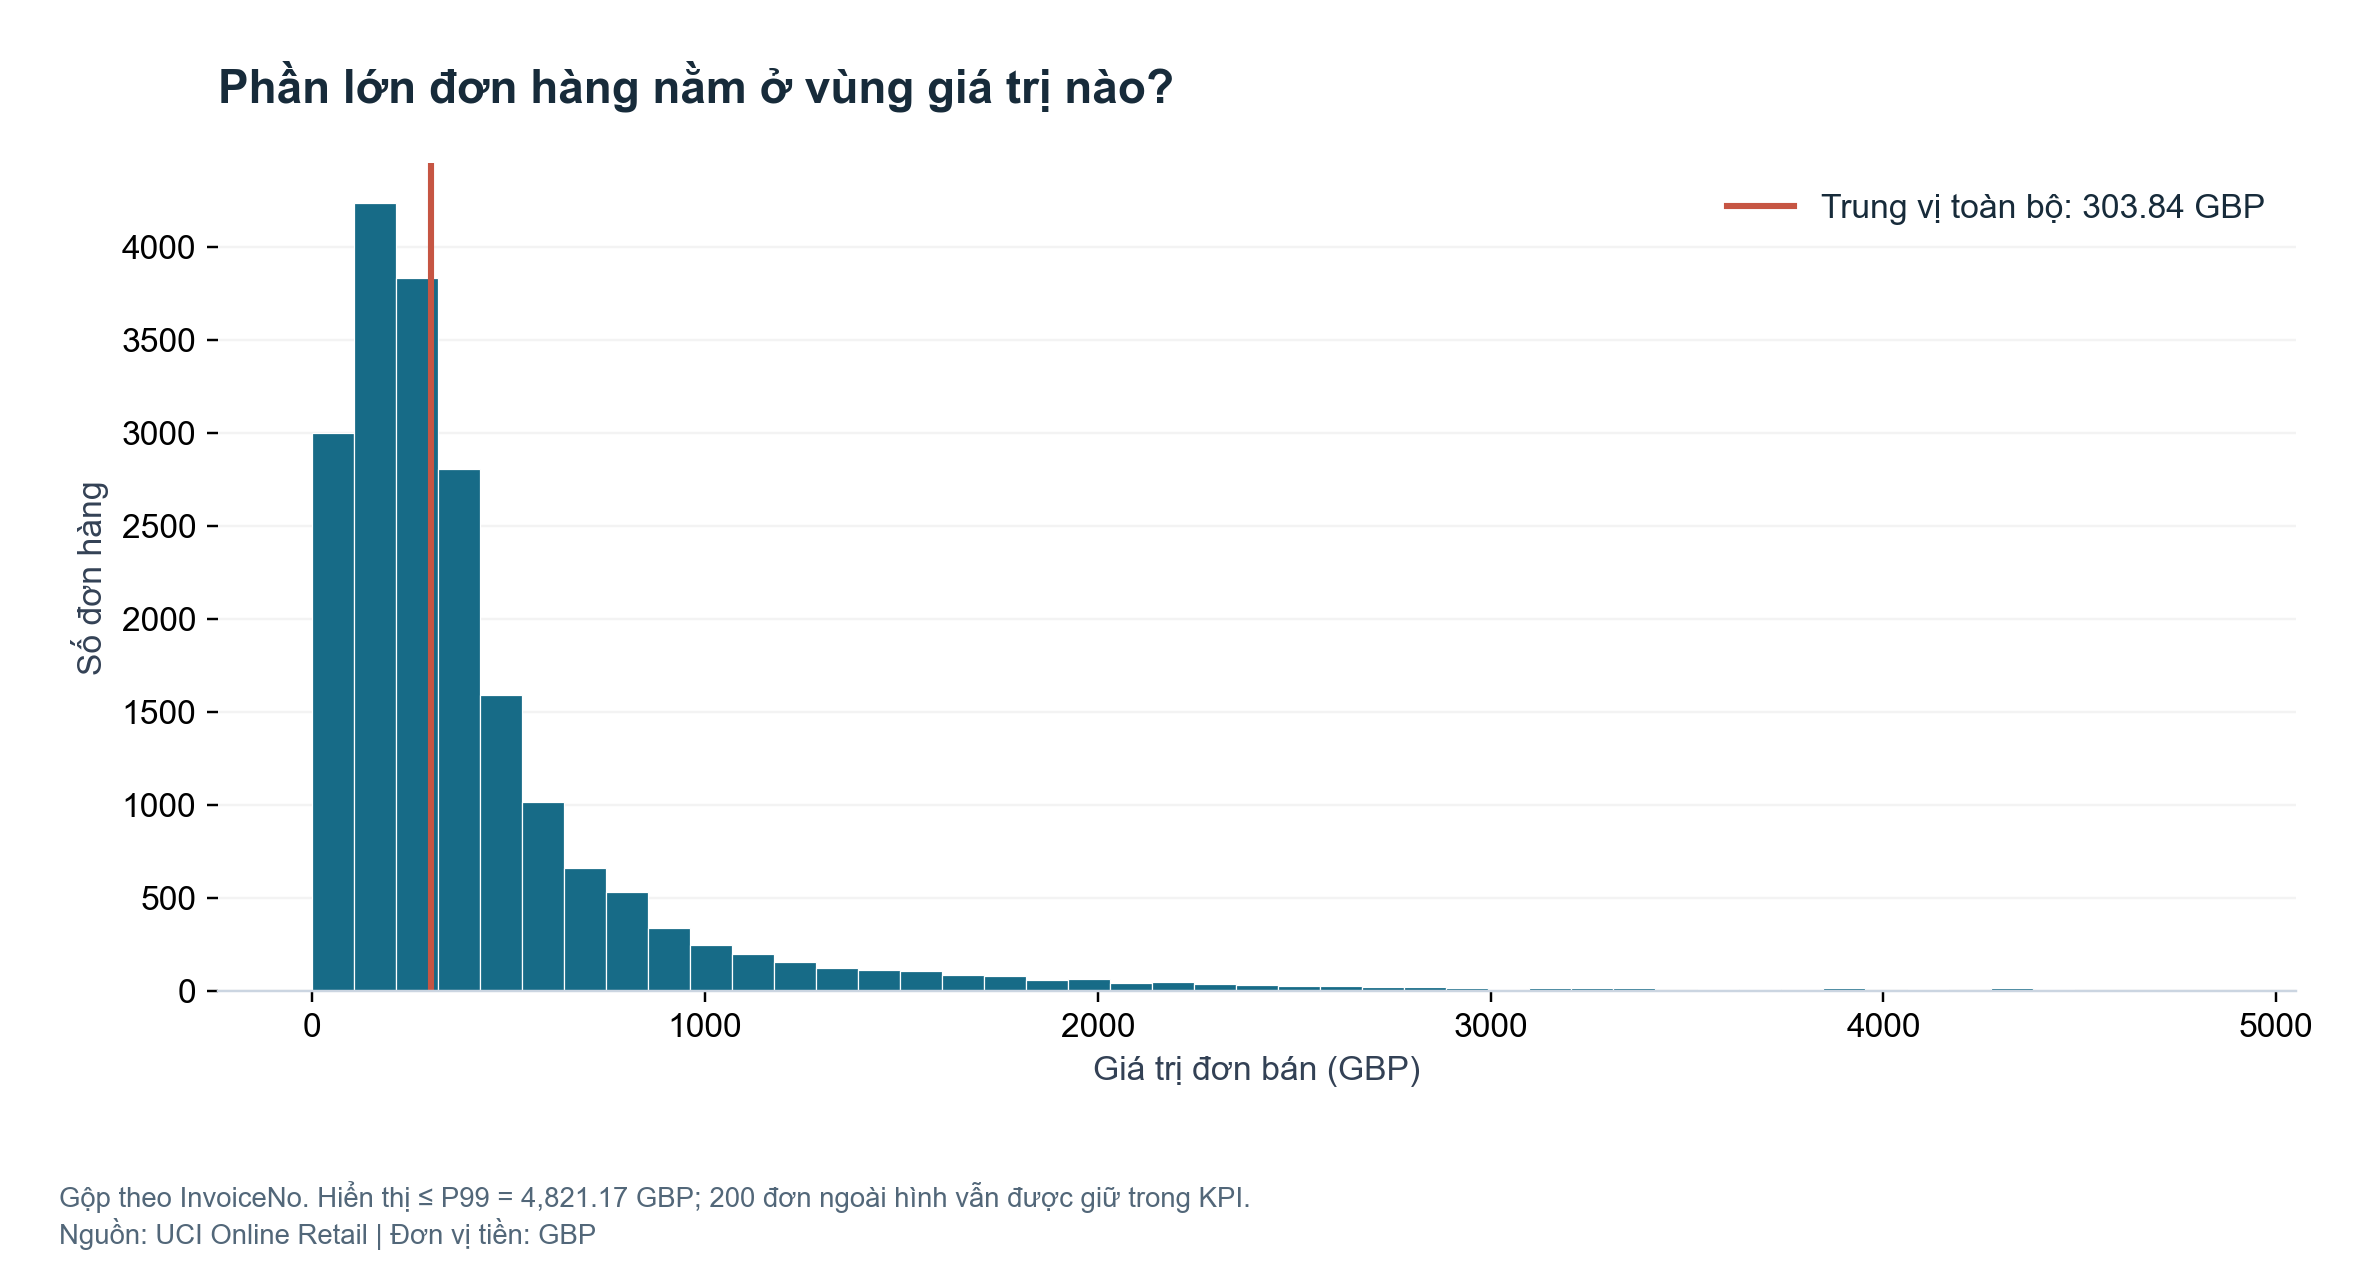

**Phát hiện:** Từ 19,960 đơn bán, giá trị trung vị là 303.84 GBP trong khi trung bình là 534.40 GBP. Đơn lớn nhất đạt 168,469.60 GBP; phân vị 99 là 4,821.17 GBP.

**Diễn giải:** Chênh lệch giữa trung bình và trung vị phản ánh đuôi phải dài: một số đơn lớn kéo trung bình lên. Hình chỉ hiển thị các đơn không vượt P99 để đọc phần tập trung; mọi đơn lớn vẫn nằm trong KPI. Dữ liệu nguồn có khách bán buôn, nhưng chưa thể xác định từng đơn lớn là bán buôn hay lỗi chỉ từ giá trị.

**Hành động:** Theo dõi đồng thời trung vị, trung bình và đơn giá trị lớn; kiểm tra chứng từ ngoại lệ trước khi dùng chúng để lập mục tiêu giỏ hàng.

In [9]:
st = stories[3]
display(Markdown('**' + st['title'] + '**\n\n' + st['purpose']))
display(Image(filename=str(figures[3]), width=950))
for label, key in [('Phát hiện', 'finding'), ('Diễn giải', 'meaning'), ('Hành động', 'action')]:
    display(Markdown('**' + label + ':** ' + st[key]))

### Góc nhìn 5
Đọc theo thứ tự: mục đích biểu đồ → bằng chứng → ý nghĩa → hành động.

**05 · Khác biệt thị trường: một mục tiêu không phù hợp cho tất cả**

Boxplot so sánh trung vị và độ phân tán giá trị đơn giữa năm thị trường có doanh số lớn nhất.

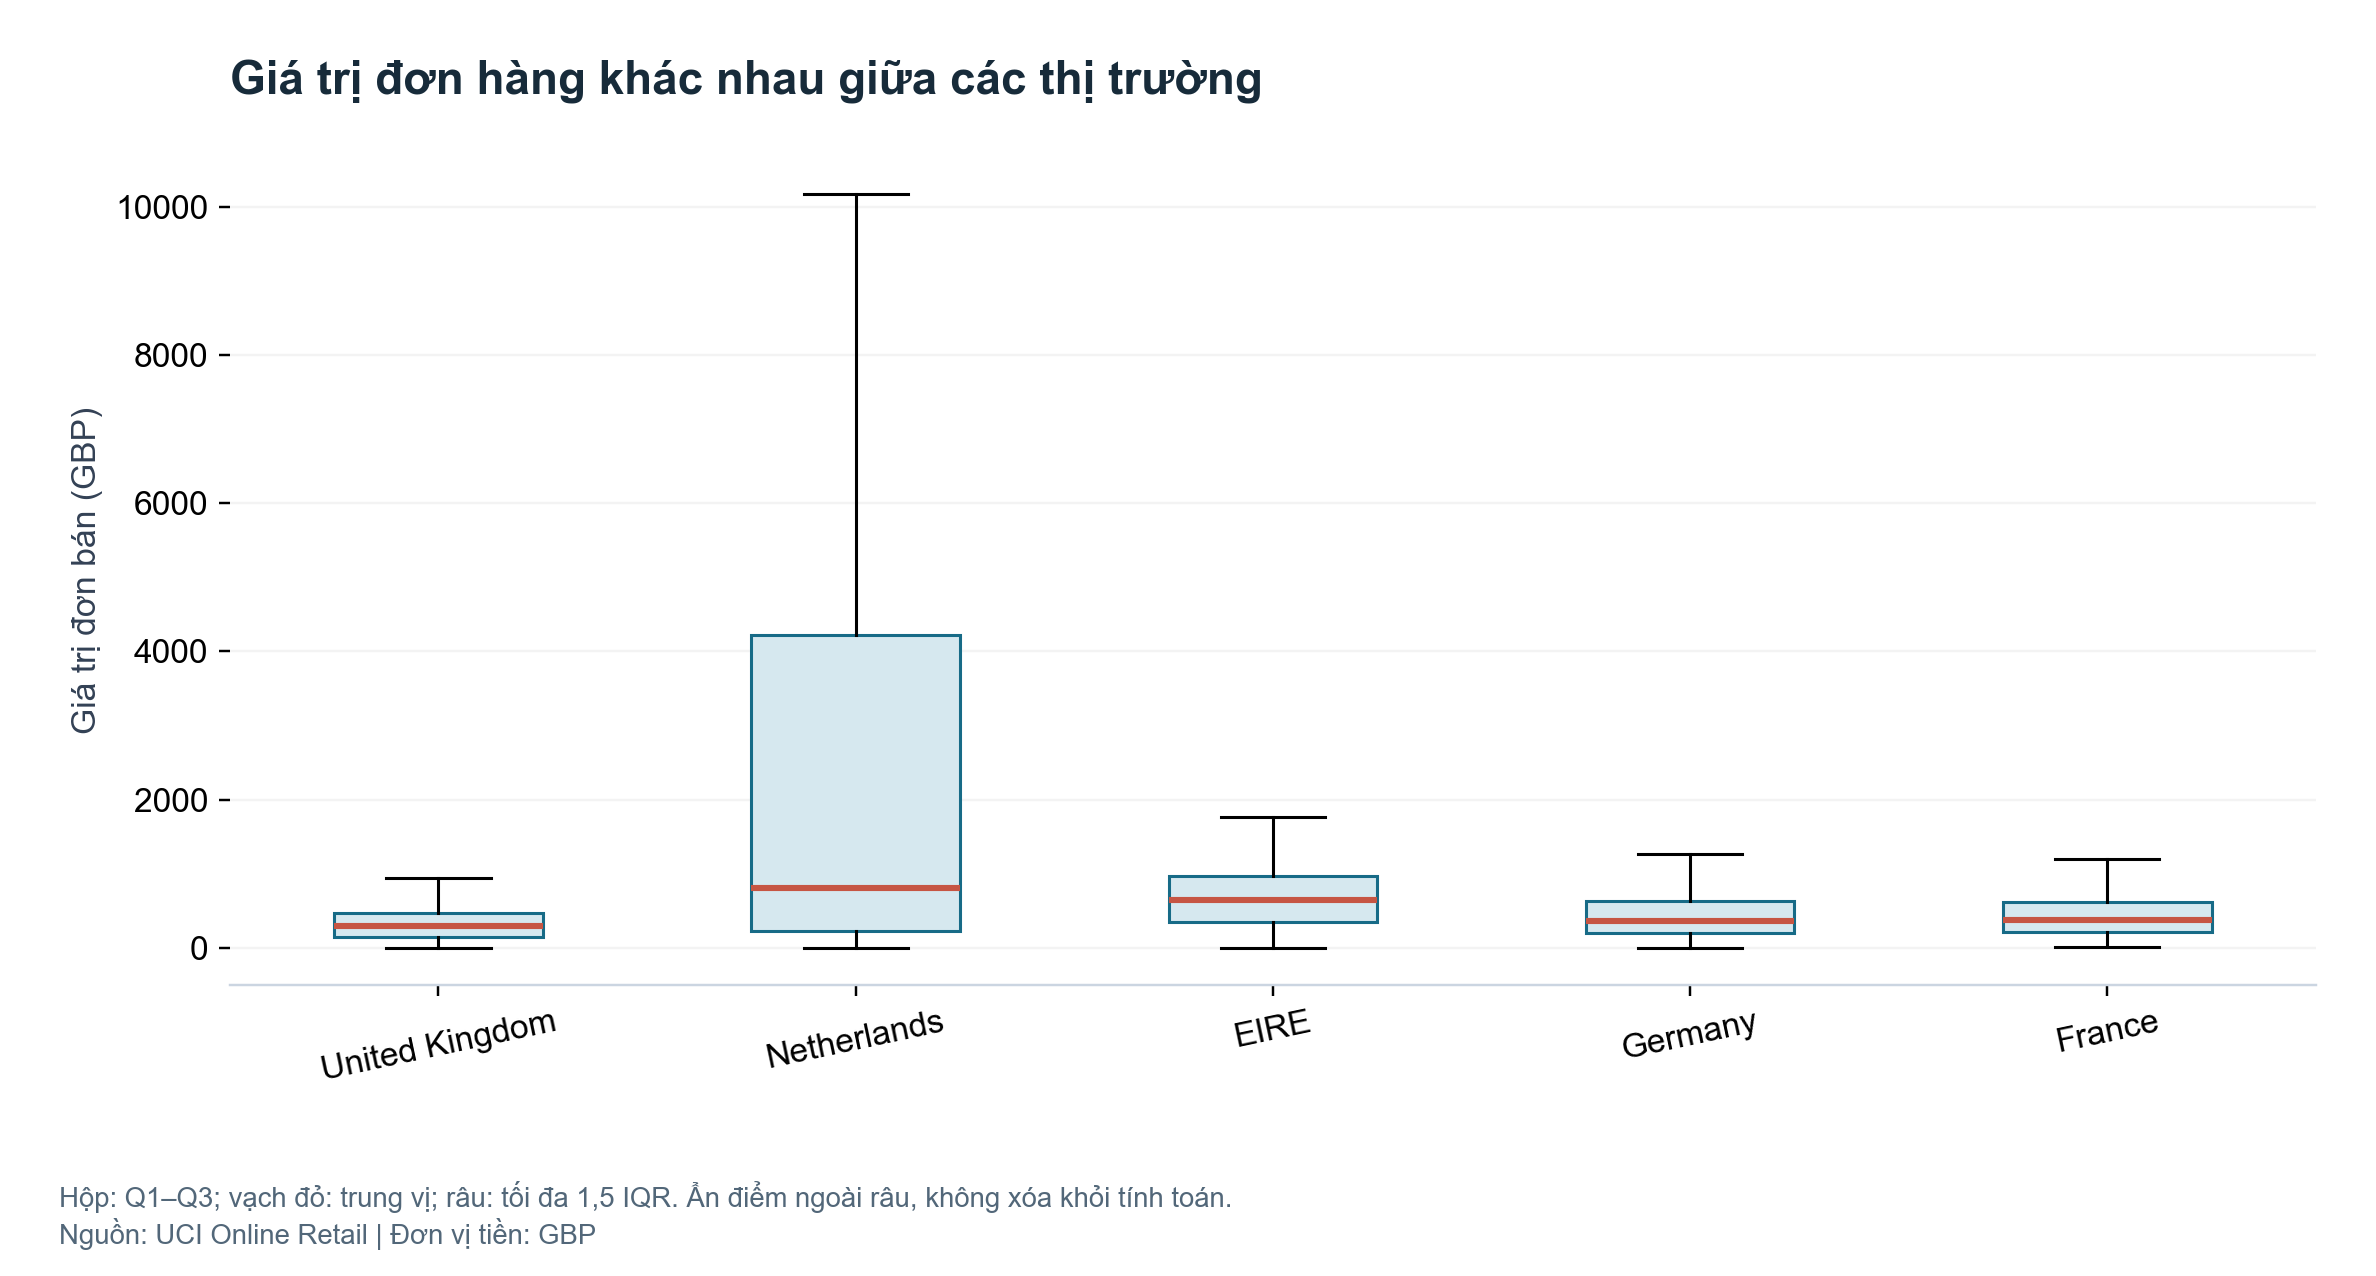

**Phát hiện:** Trong năm thị trường được chọn, trung vị giá trị đơn cao nhất ở Netherlands: 806.88 GBP; thấp nhất ở United Kingdom: 300.50 GBP. Quy mô mẫu từng nước được lưu trong bảng orders.csv.

**Diễn giải:** Hộp thể hiện Q1–Q3, vạch đỏ là trung vị, râu giới hạn theo 1,5 IQR. Điểm ngoài râu được ẩn để hình dễ đọc nhưng vẫn tham gia tính phân vị và doanh số. Khác biệt có thể liên quan cơ cấu khách hàng hoặc sản phẩm; chưa có kiểm định hay thiết kế nhân quả để khẳng định tác động của quốc gia.

**Hành động:** Thử thiết lập mục tiêu giá trị đơn theo thị trường và kiểm tra cơ cấu khách hàng trước khi áp dụng ưu đãi chung. Đối chiếu cả quy mô mẫu và số đơn khi so sánh.

In [10]:
st = stories[4]
display(Markdown('**' + st['title'] + '**\n\n' + st['purpose']))
display(Image(filename=str(figures[4]), width=950))
for label, key in [('Phát hiện', 'finding'), ('Diễn giải', 'meaning'), ('Hành động', 'action')]:
    display(Markdown('**' + label + ':** ' + st[key]))

### Góc nhìn 6
Đọc theo thứ tự: mục đích biểu đồ → bằng chứng → ý nghĩa → hành động.

**06 · Khách hàng: ưu tiên chăm sóc dựa trên mức đóng góp**

Scatter plot thể hiện đồng thời số đơn và tổng chi tiêu. Hai trục log giữ được khách cực lớn mà vẫn đọc được phần còn lại.

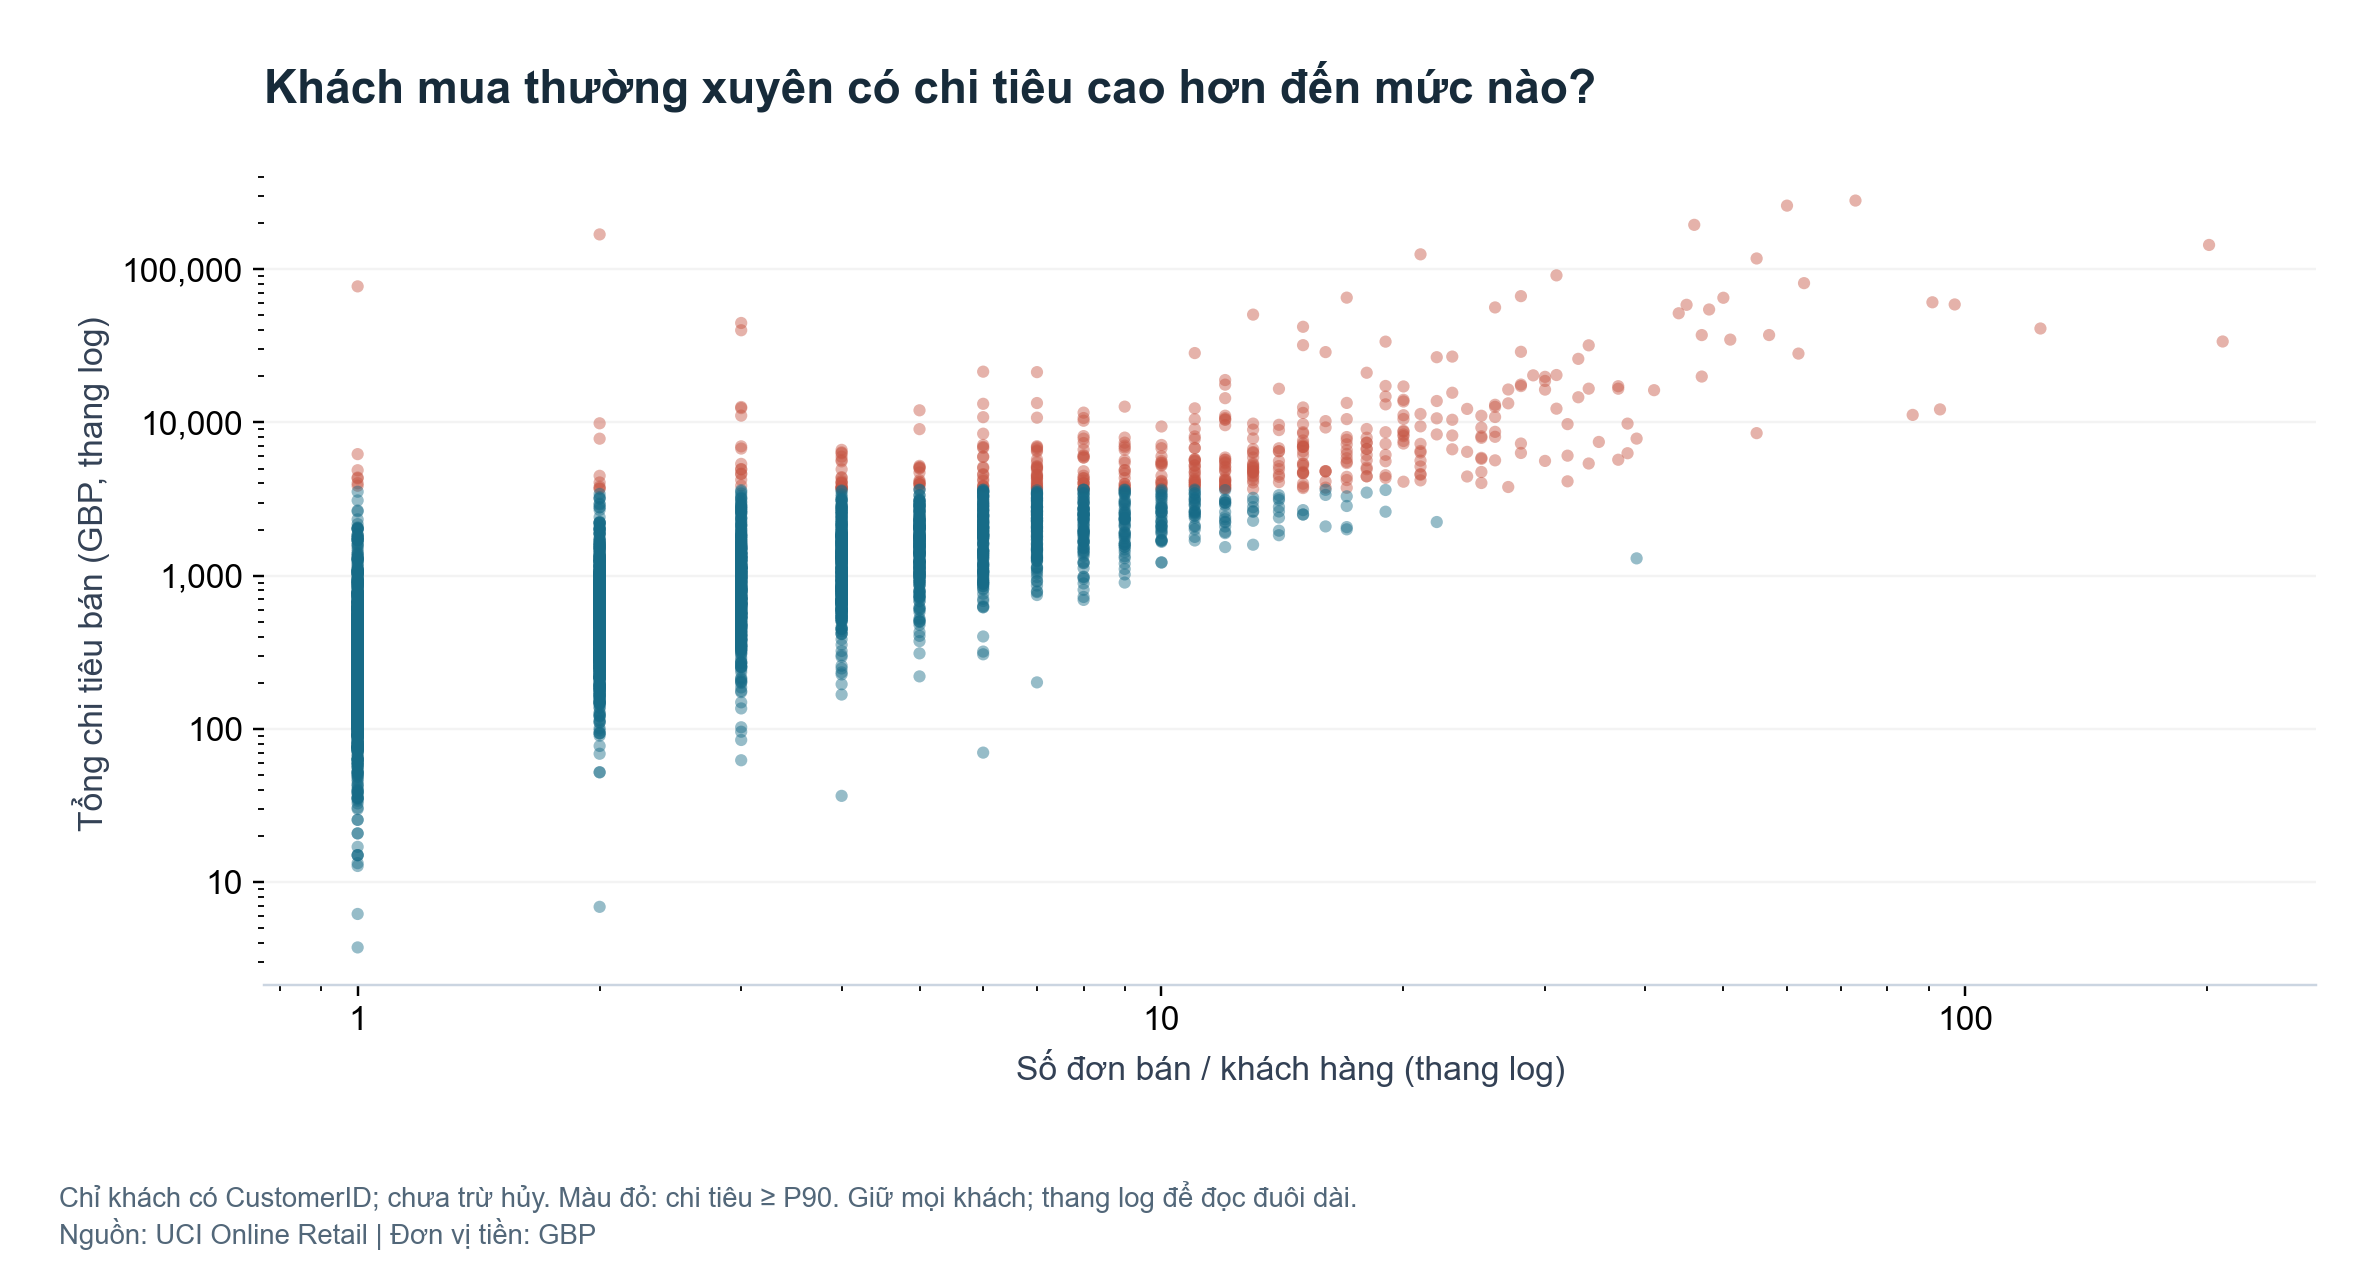

**Phát hiện:** Có 4,338 khách được định danh; doanh số của họ chiếm 83.54% tổng doanh số. Nhóm 434 khách chi tiêu cao nhất (xấp xỉ 10%) đóng góp 61.38% doanh số trong tập khách được định danh. Tương quan Spearman giữa số đơn và chi tiêu là 0.807.

**Diễn giải:** Tổng chi tiêu được cộng từ đơn mua nên quan hệ với số đơn có thành phần cơ học; tương quan không chứng minh tăng tần suất sẽ gây tăng chi tiêu. Màu đỏ chỉ nhóm chi tiêu từ P90 trở lên; ranh giới có thể bao gồm đồng hạng. Tỷ trọng top 10% trong lời dẫn dùng số khách làm tròn lên và xếp hạng xác định.

**Hành động:** Ưu tiên chăm sóc khách đóng góp cao và theo dõi mức độ phụ thuộc doanh số vào họ. Bổ sung dữ liệu mới nhất, giao dịch hủy và chi phí phục vụ trước khi xác định giá trị vòng đời hoặc chạy chương trình giữ chân.

In [11]:
st = stories[5]
display(Markdown('**' + st['title'] + '**\n\n' + st['purpose']))
display(Image(filename=str(figures[5]), width=950))
for label, key in [('Phát hiện', 'finding'), ('Diễn giải', 'meaning'), ('Hành động', 'action')]:
    display(Markdown('**' + label + ':** ' + st[key]))

## 6. Kiểm chứng và xuất sản phẩm
Kiểm tra tổng theo đơn, tháng và thị trường bằng tổng doanh số; tổng khách bằng phần doanh số có định danh. Kiểm tra đủ sáu ảnh và kỳ chưa đầy đủ. Ô cuối tạo báo cáo PDF, bản Markdown và kịch bản thuyết trình từ đúng số liệu vừa tính.

In [12]:
result = validate(data, tables, figures)
print(result)
build_report(ROOT, data, tables, figures)
build_presentation(ROOT, tables)
(ROOT / 'outputs/validation.txt').write_text(result + '\n', encoding='utf-8')
print('Báo cáo:', ROOT / 'outputs/bao_cao_visual_analytics.pdf')

PASS: dữ liệu, phân nhóm, 6 biểu đồ, đối soát đơn/tháng/thị trường/khách hàng.


Báo cáo: D:\bi_bt7\outputs\bao_cao_visual_analytics.pdf


## 7. Tự kiểm tra trước khi trình bày
1. Tại sao 541.909 dòng không phải 541.909 đơn?
2. Tại sao không bỏ mọi CustomerID thiếu?
3. Mẫu số của thanh chồng và chỉ số giá trị hủy/doanh số khác nhau thế nào?
4. Vì sao không kết luận tăng trưởng gây ra bởi quảng cáo?
5. Biểu đồ có ẩn ngoại lệ không, và KPI có còn tính ngoại lệ không?

Đáp án và kịch bản trình bày nằm trong `outputs/thuyet_trinh.md`. Có thể xem toàn bộ thuật toán qua `src/analysis.py` và tài liệu `docs/phuong_phap.md`.